In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def compute_video_optical_flow(video_path, target_cx, target_cy):
    cap = cv2.VideoCapture(video_path)
    ret1, frame1 = cap.read()
    ret2, frame2 = cap.read()
    cap.release()
    #Convert frames to grayscale and normalize
    img1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    img2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    Ix = np.zeros_like(img1)
    Iy = np.zeros_like(img1)
    Ix[:, :-1] = img1[:, 1:] - img1[:, :-1]
    Iy[:-1, :] = img1[1:, :] - img1[:-1, :]
    It = img2 - img1

    w = 1
    # Ensure window boundaries stay inside the frame limits
    y_min, y_max = max(0, target_cy - w), min(img1.shape[0], target_cy + w + 1)
    x_min, x_max = max(0, target_cx - w), min(img1.shape[1], target_cx + w + 1)
    Ix_win = Ix[y_min:y_max, x_min:x_max].flatten()
    Iy_win = Iy[y_min:y_max, x_min:x_max].flatten()
    It_win = It[y_min:y_max, x_min:x_max].flatten()

    A = np.column_stack((Ix_win, Iy_win))
    b = -It_win
    velocity, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
    dx_est, dy_est = abs(velocity[0]), abs(velocity[1])

    print(f"Estimated Motion Matrix Solution at ({target_cx}, {target_cy}):")
    print(f"dx = {dx_est:.4f} pixels/frame")
    print(f"dy = {dy_est:.4f} pixels/frame")

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    frame1_rgb = cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)
    frame2_rgb = cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB)
    axes[0].imshow(frame1_rgb)
    axes[0].set_title('Frame 1 (Time: t)')
    axes[0].plot(target_cx, target_cy, 'go', markersize=8, label='Selected Pixel Center')
    axes[0].legend(loc='upper left')

    axes[1].imshow(frame2_rgb)
    axes[1].set_title('Frame 2 (Time: t + Delta t)')
    axes[1].plot(target_cx, target_cy, 'bo', markersize=2, alpha=0.5, label='Original Start Position')
    axes[1].plot(target_cx+2.375, target_cy+0.8220, 'ro', markersize=2, alpha=0.5, label='Estimated trajectory')
    axes[1].legend(loc='upper left')
    plt.tight_layout()
    plt.show()


Estimated Motion Matrix Solution at (600, 1000):
dx = 2.3735 pixels/frame
dy = 0.8820 pixels/frame


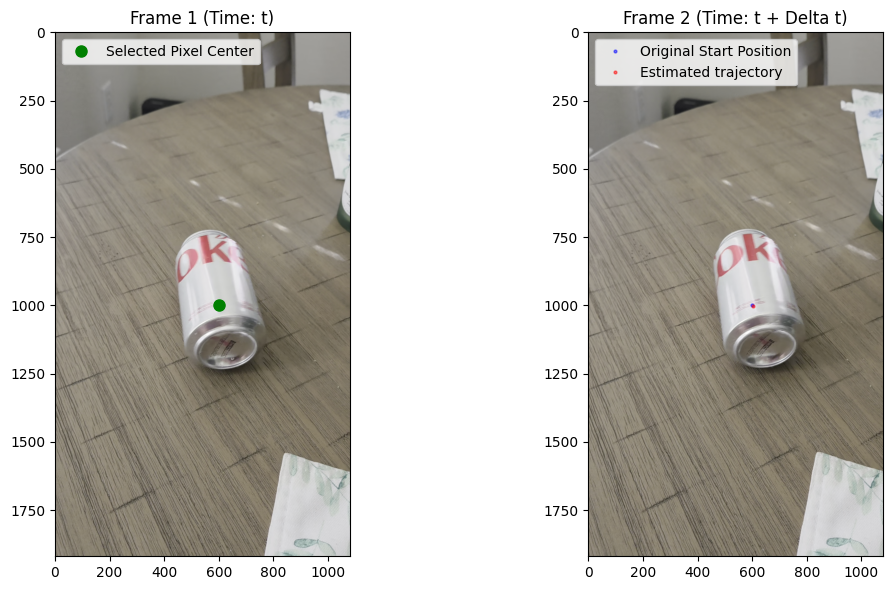

In [ ]:
VIDEO_FILE = "20261022_142922.mp4" 
PIXEL_X = 600 
PIXEL_Y = 1000 
compute_video_optical_flow(VIDEO_FILE, PIXEL_X, PIXEL_Y)

It cannot be too big because we are using a linear approximation that is accuate for small changes, so if the objects moves too far too quickly, the approximation won't be very good anymore.

In [78]:
#QUESTION 2
import numpy as np
def grad_c(x, y):
    c = np.exp(-((x - 2)**2 + (y - 1)**2) / 2)
    return np.array([(2-x) * c, (1-y) * c])
dt = 0.5
t_max = 8.0
n_steps = int(t_max / dt)
r = np.array([1.0, 0.0])
history = [(0.0, r[0], r[1])]
t_vals = np.arange(0, 8.5, dt)
r_euler = np.zeros((len(t_vals), 2))
r_euler[0] = [1.0, 0.0]
for step in range(1, n_steps + 1):
    t = step * dt
    g = grad_c(r[0], r[1])
    r = r + dt * g
    history.append((t, r[0], r[1]))
    r_euler[step] = ([r[0], r[1]])
print(f"{'Time (t)'}{'Position Vector r(t)'}")
print("-" * 35)
for t, x, y in history:
    print(f"{t}[{x}, {y}]")


Time (t)Position Vector r(t)
-----------------------------------
0.0[1.0, 0.0]
0.5[1.1839397205857212, 0.18393972058572117]
1.0[1.3935786493144988, 0.39357864931449876]
1.5[1.6034890985369346, 0.6034890985369346]
2.0[1.7729014104972967, 0.7729014104972968]
2.5[1.8807429894057013, 0.8807429894057014]
3.0[1.9395294462122026, 0.9395294462122026]
3.5[1.969654364032987, 0.9696543640329871]
4.0[1.984813216442542, 0.984813216442542]
4.5[1.9924048570955262, 0.9924048570955261]
5.0[1.9962022094866314, 0.9962022094866314]
5.5[1.998101077355343, 0.9981010773553429]
6.0[1.9990505352540082, 0.9990505352540082]
6.5[1.999525267199041, 0.999525267199041]
7.0[1.9997626335460248, 0.9997626335460249]
7.5[1.9998813167663254, 0.9998813167663255]
8.0[1.999940658382327, 0.9999406583823269]


In [77]:
r[1]

np.float64(0.9999406583823269)

In [82]:
r_leap = np.zeros((len(t_vals), 2))
r_leap[0] = [1.0, 0.0]
r_leap[1] = r_euler[1]  # Obtain r1 using Forward Euler

for n in range(1, len(t_vals) - 1):
  r_leap[n + 1] = r_leap[n - 1] + 2.0 * dt * grad_c(r_leap[n][0], r_leap[n][1])
r_leap


array([[ 1.        ,  0.        ],
       [ 1.18393972,  0.18393972],
       [ 1.41927786,  0.41927786],
       [ 1.59842365,  0.59842365],
       [ 1.76104653,  0.76104653],
       [ 1.82411539,  0.82411539],
       [ 1.93157339,  0.93157339],
       [ 1.89222236,  0.89222236],
       [ 2.03810632,  1.03810632],
       [ 1.85417134,  0.85417134],
       [ 2.18086653,  1.18086653],
       [ 1.67912571,  0.67912571],
       [ 2.47034738,  1.47034738],
       [ 1.30212583,  0.30212583],
       [ 2.89915589,  1.89915589],
       [ 0.90152115, -0.09847885],
       [ 3.22781657,  2.22781657]])

In [85]:
r_rk2 = np.zeros((len(t_vals), 2))
r_rk2[0] = [1.0, 0.0]
for n in range(len(t_vals) - 1):
  rn = r_rk2[n]
  k1 = grad_c(rn[0], rn[1])
  rmid = rn + (dt / 2.0) * k1
  k2 = grad_c(rmid[0], rmid[1])
  r_rk2[n + 1] = rn + dt * k2
r_rk2

array([[1.        , 0.        ],
       [1.19906107, 0.19906107],
       [1.4134441 , 0.4134441 ],
       [1.60461025, 0.60461025],
       [1.74571896, 0.74571896],
       [1.83944372, 0.83944372],
       [1.89927419, 0.89927419],
       [1.93695634, 0.93695634],
       [1.96057597, 0.96057597],
       [1.97535469, 0.97535469],
       [1.9845954 , 0.9845954 ],
       [1.99037181, 0.99037181],
       [1.9939823 , 0.9939823 ],
       [1.99623892, 0.99623892],
       [1.99764932, 0.99764932],
       [1.99853082, 0.99853082],
       [1.99908176, 0.99908176]])

In [89]:
d_euler = np.linalg.norm(r_euler - np.array([2, 1]), axis=1)
d_leap = np.linalg.norm(r_leap - np.array([2, 1]), axis=1)
d_rk2 = np.linalg.norm(r_rk2 - np.array([2, 1]), axis=1)

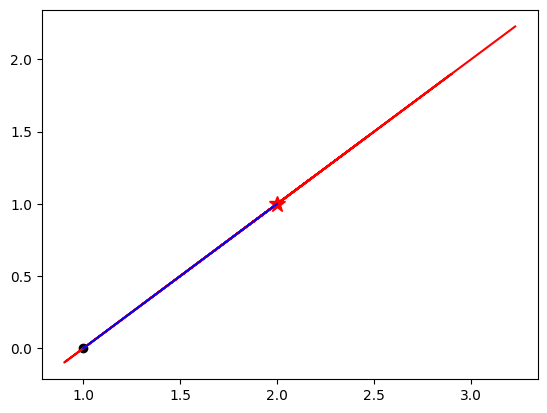

In [90]:
plt.plot(1, 0, "ko", label="Start (1,0)")
plt.plot(2, 1, "r*", markersize=12, label="Infection (2,1)")
plt.plot(r_euler[:, 0], r_euler[:, 1], "g-", label="Forward Euler")
plt.plot(r_leap[:, 0], r_leap[:, 1], "r-", label="Leapfrog")
plt.plot(r_rk2[:, 0], r_rk2[:, 1], "b-", label="RK2")

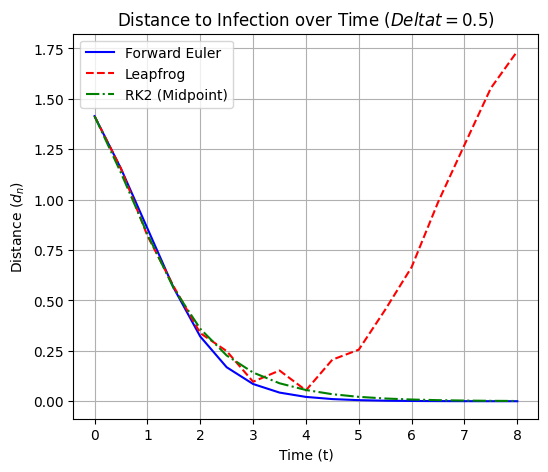

In [94]:
plt.figure(figsize=(6, 5))
plt.plot(t_vals, d_euler, "b-", label="Forward Euler")
plt.plot(t_vals, d_leap, "r--", label="Leapfrog")
plt.plot(t_vals, d_rk2, "g-.", label="RK2 (Midpoint)")
plt.xlabel("Time (t)")
plt.ylabel("Distance ($d_n$)")
plt.title(f"Distance to Infection over Time ($Delta t = {dt}$)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#QUESTION 3
X = np.array([
    [100,   0,  0],
    [  0,  80,  0],
    [  0,   0, 60],
    [ 70,  50, 40],
    [-40,  30, 50],
    [ 40, -60, 20]
]).T

Y = np.array([
    [ 77.3,  53.8, 34.4],
    [-50.3,  59.5, 19.6],
    [ -7.2, -23.9, 54.3],
    [ 17.4,  58.5, 72.6],
    [-55.5, -19.3, 38.9],
    [ 65.8, -31.2, 17.5]
]).T

A = np.dot(Y, X.T)
U, S, Vt = np.linalg.svd(A, full_matrices=False)
R = np.dot(U, Vt)
np.dot(R.T, R)

array([[ 1.00000000e+00,  1.62145052e-17, -6.62247259e-18],
       [ 1.62145052e-17,  1.00000000e+00,  8.08305395e-17],
       [-6.62247259e-18,  8.08305395e-17,  1.00000000e+00]])

In [73]:
difference = (np.dot(R, X)) - Y
squared_errors = np.sum(difference**2, axis=0)
rmse = np.sqrt(np.mean(squared_errors))
rmse

np.float64(0.31288260200676793)

FE at t=2: 0.4167867090728836
BE at t=2: 0.4722340358883469
Exact at t=2: 0.4472135954999579
h=0.25: FE Error = 3.042689e-02, BE Error = 2.502044e-02
h=0.125: FE Error = 1.086222e-01, BE Error = 1.486367e-01
h=0.0625: FE Error = 2.476565e-01, BE Error = 2.707394e-01

FE points:
(0.00, 1.0000)
(0.25, 0.7500)
(0.50, 0.6445)
(0.75, 0.5776)
(1.00, 0.5294)
(1.25, 0.4923)
(1.50, 0.4625)
(1.75, 0.4378)
(2.00, 0.4168)

BE points:
(0.00, 1.0000)
(0.25, 0.8477)
(0.50, 0.7445)
(0.75, 0.6695)
(1.00, 0.6122)
(1.25, 0.5667)
(1.50, 0.5295)
(1.75, 0.4986)
(2.00, 0.4722)


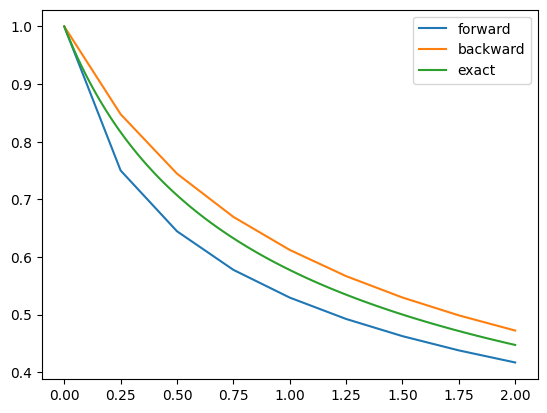

In [69]:
import numpy as np

def exact_sol(t):
    return 1.0 / np.sqrt(1.0 + 2.0 * t)

def forward_euler(h):
    t_vals = np.arange(0, 2.25, 0.25)
    y_vals = np.zeros(len(t_vals))
    y_vals[0] = 1.0
    for n in range(len(t_vals) - 1):
        y_vals[n+1] = y_vals[n] + h * (-y_vals[n]**3)
    return t_vals, y_vals

def backward_euler(h):
    t_vals = np.arange(0,2.25, 0.25)
    y_vals = np.zeros(len(t_vals))
    y_vals[0] = 1.0
    for n in range(len(t_vals) - 1):
        yn = y_vals[n]
        # Newton's method to solve: F(y) = y - yn - h * (-y^3) = y - yn + h * y^3 = 0
        # F'(y) = 1 + 3 * h * y^2
        y_guess = yn # initial guess
        while True:
            F = y_guess - yn + h * (y_guess**3)
            dF = 1.0 + 3.0 * h * (y_guess**2)
            y_next = y_guess - F / dF
            if abs(y_next - y_guess) < 1e-10:
                y_guess = y_next
                break
            y_guess = y_next
        y_vals[n+1] = y_guess
    return t_vals, y_vals

# Part (a) and (b) with h = 0.25
t_fe, y_fe = forward_euler(0.25)
t_be, y_be = backward_euler(0.25)
t_exact = np.linspace(0, 2, 100)
y_exact = exact_sol(t_exact)

print("FE at t=2:", y_fe[-1])
print("BE at t=2:", y_be[-1])
print("Exact at t=2:", exact_sol(2.0))
plt.plot(t_fe, y_fe, label='forward')
plt.plot(t_be, y_be, label='backward')
plt.plot(t_exact, y_exact, label='exact')
plt.legend()

# Part (d) errors
h_list = [0.25, 0.125, 0.0625]
exact_t2 = exact_sol(2.0)
results = []
for h in h_list:
    _, y_f = forward_euler(h)
    _, y_b = backward_euler(h)
    err_f = abs(y_f[-1] - exact_t2)
    err_b = abs(y_b[-1] - exact_t2)
    results.append((h, err_f, err_b))

for res in results:
    print(f"h={res[0]}: FE Error = {res[1]:.6e}, BE Error = {res[2]:.6e}")

# Let's print out data for plotting to use in chart placeholder
print("\nFE points:")
for t, y in zip(t_fe, y_fe):
    print(f"({t:.2f}, {y:.4f})")
print("\nBE points:")
for t, y in zip(t_be, y_be):
    print(f"({t:.2f}, {y:.4f})")
